##Name: Sanjana Bondre
##Roll no.: C2_28
##Project Title: Smart Waste Classification and Recommendation System
#Deep Learning Lab

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

print("Environment setup successful!")


TensorFlow version: 2.21.0
GPU available: True
Environment setup successful!


In [ ]:

from google.colab import files

uploaded = files.upload()



Saving archive.zip to archive.zip


In [ ]:

import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/waste_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files and folders found:")

for item in os.listdir(extract_path):
    print(item)


Dataset extracted successfully!
Files and folders found:
dataset-resized


In [ ]:

import os

dataset_path = "/content/waste_dataset/dataset-resized"

print("Waste categories:\n")

for category in sorted(os.listdir(dataset_path)):
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        images = [
            f for f in os.listdir(category_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        print(f"{category}: {len(images)} images")

print("\nDataset inspection completed!")


Waste categories:

cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images

Dataset inspection completed!


In [ ]:

!pip -q install split-folders

import splitfolders

input_folder = "/content/waste_dataset/dataset-resized"
output_folder = "/content/waste_split"

splitfolders.ratio(
    input_folder,
    output=output_folder,
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

print("Dataset split completed!")


Copying files: 2527 files [00:00, 5899.03 files/s]

Dataset split completed!


In [ ]:

import tensorflow as tf

# Dataset folders
train_dir = "/content/waste_split/train"
val_dir = "/content/waste_split/val"
test_dir = "/content/waste_split/test"

# Image settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training images
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED
)

# Load validation images
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Load testing images
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("\nWaste categories:", class_names)
print("Number of categories:", len(class_names))
print("\nImage datasets loaded successfully!")


Found 1766 files belonging to 6 classes.
Found 377 files belonging to 6 classes.
Found 384 files belonging to 6 classes.

Waste categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of categories: 6

Image datasets loaded successfully!


In [ ]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build our waste classification model
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(6, activation="softmax")
])

# Configure model training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# Train the model
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("Training completed!")


Epoch 1/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 33s 259ms/step - accuracy: 0.5668 - loss: 1.1461 - val_accuracy: 0.7268 - val_loss: 0.7567
Epoch 2/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.7678 - loss: 0.6259 - val_accuracy: 0.7905 - val_loss: 0.6065
Epoch 3/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 59ms/step - accuracy: 0.8233 - loss: 0.5000 - val_accuracy: 0.8143 - val_loss: 0.5415
Epoch 4/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8414 - loss: 0.4413 - val_accuracy: 0.8302 - val_loss: 0.5112
Epoch 5/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.8766 - loss: 0.3751 - val_accuracy: 0.8329 - val_loss: 0.4898
Epoch 6/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.8867 - loss: 0.3386 - val_accuracy: 0.8196 - val_loss: 0.4904
Epoch 7/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.9015 - loss: 0.3090 - val_accuracy: 0.8408 - val_loss: 0.4706
Epoch 8/10
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.9088 - loss: 0.2734 - val_accuracy: 0.8462 -

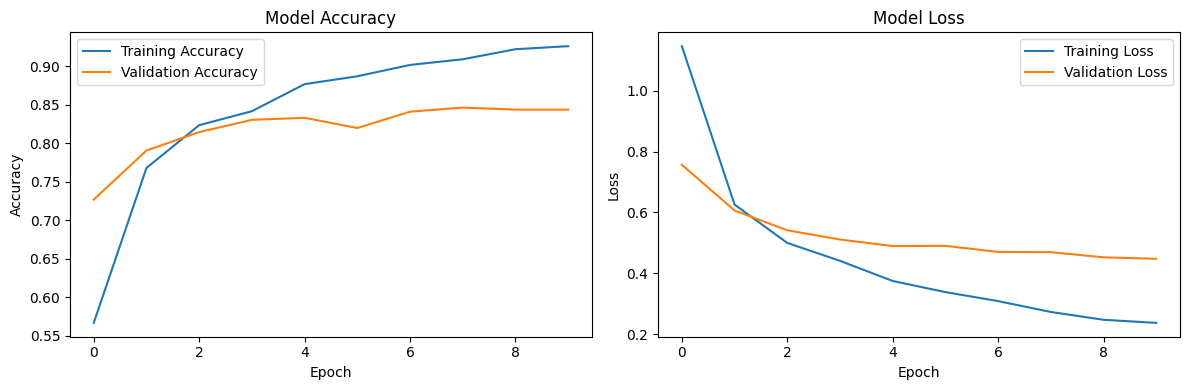

In [ ]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8307 - loss: 0.4936
Test Loss: 0.4936
Test Accuracy: 83.07%


12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step
              precision    recall  f1-score   support

   cardboard       0.94      0.84      0.89        61
       glass       0.87      0.70      0.77        76
       metal       0.82      0.85      0.83        62
       paper       0.83      0.89      0.86        90
     plastic       0.75      0.90      0.82        73
       trash       0.80      0.73      0.76        22

    accuracy                           0.83       384
   macro avg       0.84      0.82      0.82       384
weighted avg       0.84      0.83      0.83       384



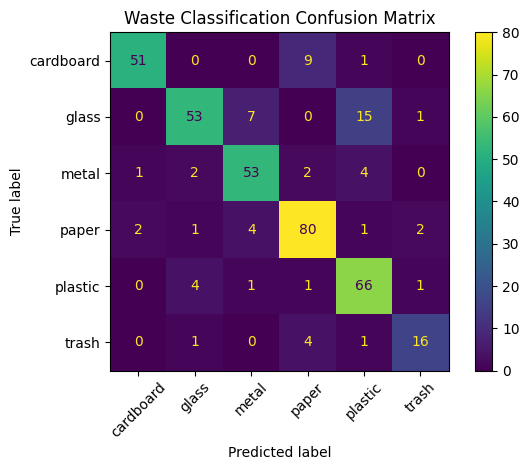

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Actual labels
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

# Predicted labels
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(xticks_rotation=45)
plt.title("Waste Classification Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

model.save("/content/waste_classifier_stage1.keras")
print("Stage 1 model saved successfully!")


Stage 1 model saved successfully!


In [ ]:

# Unfreeze the MobileNetV2 base model
base_model.trainable = True

# Keep most layers frozen; train only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))
print("Fine-tuning setup completed!")


Trainable layers: 19
Fine-tuning setup completed!


In [ ]:

fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

print("Fine-tuning completed!")


Epoch 1/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 24s 235ms/step - accuracy: 0.9320 - loss: 0.2019 - val_accuracy: 0.8515 - val_loss: 0.4317
Epoch 2/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.9530 - loss: 0.1584 - val_accuracy: 0.8594 - val_loss: 0.4244
Epoch 3/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9581 - loss: 0.1371 - val_accuracy: 0.8647 - val_loss: 0.4205
Epoch 4/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9672 - loss: 0.1218 - val_accuracy: 0.8621 - val_loss: 0.4098
Epoch 5/5
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9768 - loss: 0.0991 - val_accuracy: 0.8806 - val_loss: 0.4047
Fine-tuning completed!


In [ ]:

fine_loss, fine_accuracy = model.evaluate(test_ds)

print(f"Stage 2 Test Accuracy: {fine_accuracy * 100:.2f}%")


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8438 - loss: 0.4823
Stage 2 Test Accuracy: 84.38%


In [ ]:

# Record the results from both stages
stage1_accuracy = 82.00  # From your Stage 1 classification report
stage2_accuracy = fine_accuracy * 100

print("MODEL PERFORMANCE COMPARISON")
print("-" * 35)
print(f"Stage 1 Test Accuracy: {stage1_accuracy:.2f}%")
print(f"Stage 2 Test Accuracy: {stage2_accuracy:.2f}%")
print(f"Difference: {stage2_accuracy - stage1_accuracy:+.2f} percentage points")

# Save the fine-tuned model
model.save("/content/waste_classifier_final.keras")
print("\nFinal model saved successfully!")


MODEL PERFORMANCE COMPARISON
-----------------------------------
Stage 1 Test Accuracy: 82.00%
Stage 2 Test Accuracy: 84.38%
Difference: +2.38 percentage points

Final model saved successfully!


Saving Screenshot 2026-10-21 192106.png to Screenshot 2026-10-21 192106.png


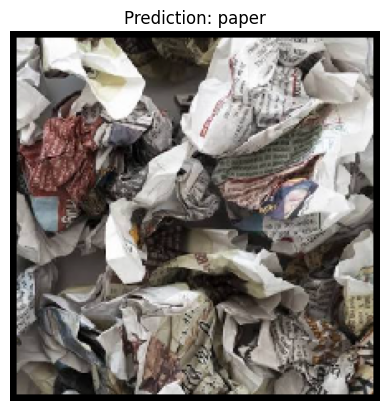

Predicted category: paper
Confidence: 98.18%


In [ ]:

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Upload an image
uploaded = files.upload()

# Get the uploaded filename
image_path = next(iter(uploaded))

# Load and prepare the image
img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict the waste category
predictions = model.predict(img_array, verbose=0)[0]
predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display result
plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {predicted_class}")
plt.show()

print("Predicted category:", predicted_class)
print(f"Confidence: {confidence:.2f}%")


In [ ]:

# Disposal guidance for each waste category
disposal_guidance = {
    "cardboard": "Keep dry and clean. Flatten boxes and place them in paper/cardboard recycling.",
    "glass": "Separate by local recycling rules. Handle broken glass carefully.",
    "metal": "Empty cans and containers, then place them in metal recycling where accepted.",
    "paper": "Keep paper clean and dry. Separate contaminated paper from recyclable paper.",
    "plastic": "Empty containers and check local recycling rules. Rinse when required.",
    "trash": "Place in the appropriate residual-waste bin. Check local rules for special disposal."
}

print("SMART WASTE CLASSIFICATION RESULT")
print("-" * 35)
print("Predicted category:", predicted_class)
print(f"Confidence: {confidence:.2f}%")
print("\nRecommended action:")
print(disposal_guidance[predicted_class])


SMART WASTE CLASSIFICATION RESULT
-----------------------------------
Predicted category: paper
Confidence: 98.18%

Recommended action:
Keep paper clean and dry. Separate contaminated paper from recyclable paper.


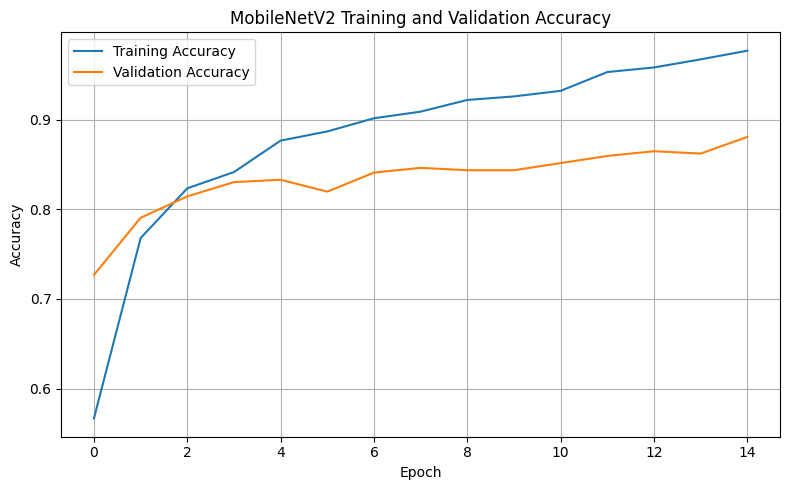

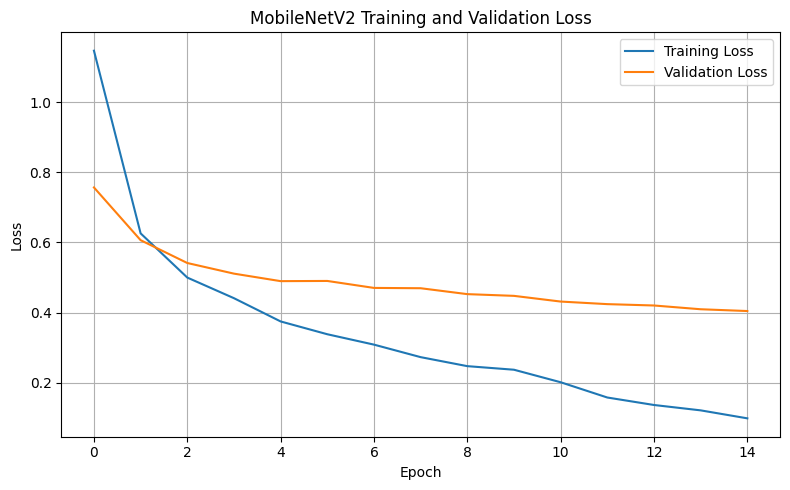

Both evaluation graphs saved!


In [ ]:

import matplotlib.pyplot as plt

# Combine histories from both training stages
train_acc = (
    history.history["accuracy"]
    + fine_tune_history.history["accuracy"]
)
val_acc = (
    history.history["val_accuracy"]
    + fine_tune_history.history["val_accuracy"]
)
train_loss = (
    history.history["loss"]
    + fine_tune_history.history["loss"]
)
val_loss = (
    history.history["val_loss"]
    + fine_tune_history.history["val_loss"]
)

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.title("MobileNetV2 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/accuracy_graph.png", dpi=300)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.title("MobileNetV2 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/content/loss_graph.png", dpi=300)
plt.show()

print("Both evaluation graphs saved!")


In [ ]:

!pip -q install gradio


In [ ]:

import gradio as gr
import numpy as np
import html
from PIL import Image
from tensorflow.keras.utils import img_to_array

# --------------------------------------------------
# 1. PROJECT SETTINGS
# --------------------------------------------------

class_names = [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
]

disposal_guidance = {
    "cardboard": "Keep dry and flatten boxes before recycling.",
    "glass": "Handle carefully and follow local glass recycling rules.",
    "metal": "Empty containers and recycle where accepted.",
    "paper": "Keep paper clean and dry for recycling.",
    "plastic": "Empty containers and check local recycling rules.",
    "trash": "Place in residual waste and check local disposal rules."
}

# --------------------------------------------------
# 2. IMAGE CONVERSION HELPER
# --------------------------------------------------

def to_pil_image(image):
    if image is None:
        return None

    if isinstance(image, np.ndarray):
        if image.dtype.kind == "f":
            if image.size and image.max() <= 1.0:
                image = image * 255

        image = np.clip(image, 0, 255).astype(np.uint8)
        image = Image.fromarray(image)

    if isinstance(image, Image.Image):
        return image

    return None

# --------------------------------------------------
# 3. CLASSIFY THE CIRCLED WASTE ITEM
# --------------------------------------------------

def classify_waste(editor_data):

    empty_result = """
    <div class="result-card">
        <h2>🌱 Welcome to EcoSort</h2>
        <p>Upload an image and draw around one waste item.</p>
    </div>
    """

    if not isinstance(editor_data, dict):
        return {}, empty_result

    background = to_pil_image(editor_data.get("background"))
    layers = editor_data.get("layers") or []

    if background is None:
        return {}, """
        <div class="result-card">
            <h2>📷 Upload an image first</h2>
            <p>Please upload an image containing a waste item.</p>
        </div>
        """

    background = background.convert("RGB")

    # Find the visible brush strokes.
    all_x = []
    all_y = []

    for layer in layers:
        layer_image = to_pil_image(layer)

        if layer_image is None:
            continue

        layer_array = np.array(layer_image.convert("RGBA"))
        mask = layer_array[:, :, 3] > 10

        if np.any(mask):
            ys, xs = np.where(mask)
            all_x.extend([int(xs.min()), int(xs.max())])
            all_y.extend([int(ys.min()), int(ys.max())])

    if not all_x or not all_y:
        return {}, """
        <div class="result-card">
            <h2>✏️ Circle an item first</h2>
            <p>Use the brush to draw a closed circle around one
            waste item, then click
            <strong>Classify Selected Waste</strong>.</p>
        </div>
        """

    # Calculate the bounding box of the brush strokes.
    x1 = min(all_x)
    y1 = min(all_y)
    x2 = max(all_x) + 1
    y2 = max(all_y) + 1

    # Add a little padding around the selected item.
    pad_x = max(8, int((x2 - x1) * 0.08))
    pad_y = max(8, int((y2 - y1) * 0.08))

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(background.width, x2 + pad_x)
    y2 = min(background.height, y2 + pad_y)

    if x2 <= x1 or y2 <= y1:
        return {}, empty_result

    # Crop internally; no separate crop preview is displayed.
    selected_crop = background.crop((x1, y1, x2, y2))

    # Prepare the crop for the trained model.
    resized_image = selected_crop.resize((224, 224))
    image_array = img_to_array(resized_image)
    image_array = np.expand_dims(image_array, axis=0)

    # Predict using the existing trained model.
    predictions = model.predict(image_array, verbose=0)[0]

    predicted_index = int(np.argmax(predictions))
    category = class_names[predicted_index]
    confidence = float(predictions[predicted_index]) * 100

    scores = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    guidance = disposal_guidance.get(
        category,
        "Check your local waste disposal guidelines."
    )

    safe_category = html.escape(category.title())
    safe_guidance = html.escape(guidance)

    result_html = f"""
    <div class="result-card">
        <div class="result-kicker">SELECTED WASTE RESULT</div>

        <div class="result-category">
            ♻️ {safe_category}
        </div>

        <div class="confidence-label">
            Model confidence:
            <strong>{confidence:.2f}%</strong>
        </div>

        <div class="confidence-track">
            <div class="confidence-fill"
                 style="width: {confidence:.2f}%;">
            </div>
        </div>

        <div class="tip-box">
            <div class="tip-heading">
                🌿 Disposal recommendation
            </div>
            <p>{safe_guidance}</p>
        </div>
    </div>
    """

    return scores, result_html

# --------------------------------------------------
# 4. NATURE-THEMED UI DESIGN
# --------------------------------------------------

custom_css = """
.gradio-container {
    max-width: 1150px !important;
    margin: auto !important;
    background: #f4f8f1;
}

#eco-banner {
    background: linear-gradient(135deg, #164e35, #398557);
    color: white;
    padding: 28px;
    border-radius: 18px;
    text-align: center;
    margin-bottom: 18px;
}

#eco-banner h1 {
    font-size: 34px;
    margin-bottom: 8px;
}

#eco-banner p {
    font-size: 16px;
    margin: 0;
}

.result-card {
    background: #ffffff;
    border: 1px solid #dce9dc;
    border-radius: 16px;
    padding: 22px;
    color: #243b2d;
    min-height: 170px;
}

.result-kicker {
    color: #4d805b;
    font-size: 12px;
    font-weight: 700;
    letter-spacing: 1.3px;
}

.result-category {
    font-size: 30px;
    font-weight: 750;
    margin: 14px 0;
    color: #205c3b;
}

.confidence-label {
    font-size: 15px;
    margin-bottom: 10px;
}

.confidence-track {
    height: 10px;
    background: #e6eee5;
    border-radius: 10px;
    overflow: hidden;
}

.confidence-fill {
    height: 100%;
    background: #45945b;
    border-radius: 10px;
}

.tip-box {
    background: #eff7ed;
    border-left: 4px solid #4d995d;
    border-radius: 8px;
    padding: 13px;
    margin-top: 20px;
}

.tip-heading {
    font-weight: 700;
    color: #285d39;
}

.tip-box p {
    margin-bottom: 0;
}

#about-section {
    background: #eaf3e7;
    padding: 18px;
    border-radius: 14px;
    margin-top: 15px;
}
"""

# --------------------------------------------------
# 5. BUILD THE GRADIO APPLICATION
# --------------------------------------------------

with gr.Blocks(
    title="EcoSort | Smart Waste Classification"
) as demo:

    gr.HTML("""
    <div id="eco-banner">
        <h1>🌿 EcoSort</h1>
        <p>Smart Waste Classification Using MobileNetV2</p>
        <p>Identify waste and make more sustainable choices.</p>
    </div>
    """)

    gr.Markdown(
        "### ♻️ Select and classify your waste\n"
        "Upload a photo containing multiple waste items. "
        "Use the drawing brush to outline **one item**, then "
        "classify the selected region."
    )

    with gr.Row():

        with gr.Column(scale=1):

            input_image = gr.ImageEditor(
                type="pil",
                label="Upload image and draw around one item",
                height=350,
                brush=gr.Brush(
                    colors=["#00FF00"],
                    default_size=8
                ),
                eraser=gr.Eraser()
            )

            gr.Markdown(
                "🖌️ **How to use:** Upload your photo, draw a "
                "closed outline around one item, and click the "
                "button. Keep the outline close to the item."
            )

            classify_button = gr.Button(
                "♻️ Classify Selected Waste",
                variant="primary",
                size="lg"
            )

        with gr.Column(scale=1):

            output_scores = gr.Label(
                num_top_classes=6,
                label="Prediction scores"
            )

            output_html = gr.HTML(
                value="""
                <div class="result-card">
                    <h2>🌱 Your results will appear here</h2>
                    <p>Upload an image and mark one waste item.</p>
                </div>
                """
            )

    # Connect the button to the classification function.
    classify_button.click(
        fn=classify_waste,
        inputs=input_image,
        outputs=[
            output_scores,
            output_html
        ]
    )

    # ABOUT SECTION
    gr.HTML("""
    <div id="about-section">
        <h3>🌎 About EcoSort</h3>
        <p>
            EcoSort uses a trained MobileNetV2 image-classification
            model to classify waste into six categories:
            cardboard, glass, metal, paper, plastic, and trash.
        </p>
        <p>
            The selected region is classified and a disposal
            recommendation is displayed to encourage responsible
            waste management.
        </p>
        <p>
            <strong>Note:</strong> The model predicts one category
            for the selected region. Results depend on image quality
            and the model's training data.
        </p>
    </div>
    """)

    # FOOTER
    gr.Markdown(
        "<center>🌱 EcoSort — Small steps toward a cleaner planet.</center>"
    )

# --------------------------------------------------
# 6. LAUNCH THE APPLICATION
# --------------------------------------------------

demo.launch(
    share=True,
    debug=True,
    theme=gr.themes.Soft(
        primary_hue="green",
        secondary_hue="lime",
        neutral_hue="stone"
    ),
    css=custom_css
)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d9e4b7640106fe9339.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
